<a href="https://colab.research.google.com/github/dhengekrunal-ai/machine-learning-MDM-LAB/blob/main/Copy_of_Task_6_EE542.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


**1. Load Dataset**

In [ ]:
file = '/content/drive/MyDrive/B.TECH/5th Sem/MDM Dataset/Dataset 6.csv'
data = pd.read_csv(file)


In [ ]:
print("Dataset Preview:")
print(data.head())

Dataset Preview:
   Signal_Strength_dBm  SNR_dB  Interference_dB  Distance_m  Frequency_GHz  \
0                  -41       6                0         257            5.0   
1                  -86      25               20         134            2.4   
2                  -73      27                0         385            2.4   
3                  -57       5                0         255            5.0   
4                  -87      15               24          61            5.0   

   Channel_Bandwidth_MHz  Noise_Floor_dBm  Connected_Devices  \
0                    160             -100                 24   
1                    160              -96                 41   
2                     20              -72                 13   
3                    160              -86                  9   
4                     20              -79                 32   

   Estimated_Throughput_Mbps Quality  
0                         18    Poor  
1                         55    Poor  
2           

In [ ]:
print("\nDataset Columns:")
print(data.columns)


Dataset Columns:
Index(['Signal_Strength_dBm', 'SNR_dB', 'Interference_dB', 'Distance_m',
       'Frequency_GHz', 'Channel_Bandwidth_MHz', 'Noise_Floor_dBm',
       'Connected_Devices', 'Estimated_Throughput_Mbps', 'Quality'],
      dtype='object')


**2. Create Signal Quality Target**

In [ ]:
print("\nDelivery Success Classes:")
print(data["Quality"].value_counts())


Delivery Success Classes:
Quality
Poor         51
Fair         37
Good         10
Excellent     2
Name: count, dtype: int64


In [ ]:
if data["Quality"].nunique() < 2:

    print("\nOnly one class detected.")
    print("Creating Signal Quality using Signal_Strength_dBm...")

    data["Signal_Quality"] = data["Signal_Strength_dBm"].apply(
        lambda x: "Good" if x > -70 else "Poor"
    )

    y = data["Signal_Quality"]

else:

    y = data["Quality"]

**3. Encode Target**

In [ ]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

In [ ]:
print("\nTarget Classes:")
print(encoder.classes_)


Target Classes:
['Excellent' 'Fair' 'Good' 'Poor']


**4. Select Feature**

In [ ]:
X = data[
    [
        "Distance_m",
        "Signal_Strength_dBm",
        "Frequency_GHz",
        "SNR_dB",
        "Interference_dB",
        "Channel_Bandwidth_MHz",
        "Noise_Floor_dBm",
        "Connected_Devices",
        "Estimated_Throughput_Mbps"
    ]
]

**5. Feature Scaling**

In [ ]:
scaler = StandardScaler()


X = scaler.fit_transform(X)

**6. Train-Test Split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42,

    stratify=y

)


**7. SVM Model**

In [ ]:
model = SVC(

    kernel="rbf",

    C=1,

    gamma="scale"

)

In [ ]:
# Training

model.fit(

    X_train,

    y_train

)

SVC(C=1)

**8. Prediction**

In [ ]:
y_pred = model.predict(

    X_test

)

** 9. Evaluation**

In [ ]:
print("\nAccuracy:")

print(

    round(
        accuracy_score(
            y_test,
            y_pred
        )*100,
        2
    ),

    "%"

)



Accuracy:
60.0 %


In [ ]:
print("\nClassification Report:")


print(

    classification_report(

        y_test,

        y_pred,

        target_names=encoder.classes_

    )

)


Classification Report:
              precision    recall  f1-score   support

   Excellent       0.00      0.00      0.00         1
        Fair       0.50      0.43      0.46         7
        Good       0.00      0.00      0.00         2
        Poor       0.64      0.90      0.75        10

    accuracy                           0.60        20
   macro avg       0.29      0.33      0.30        20
weighted avg       0.50      0.60      0.54        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**10. Confusion Matrix**

In [ ]:
cm = confusion_matrix(

    y_test,

    y_pred

)

<Axes: >

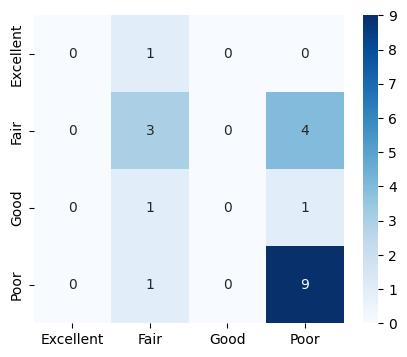

In [ ]:
plt.figure(figsize=(5,4))


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=encoder.classes_,

    yticklabels=encoder.classes_

)

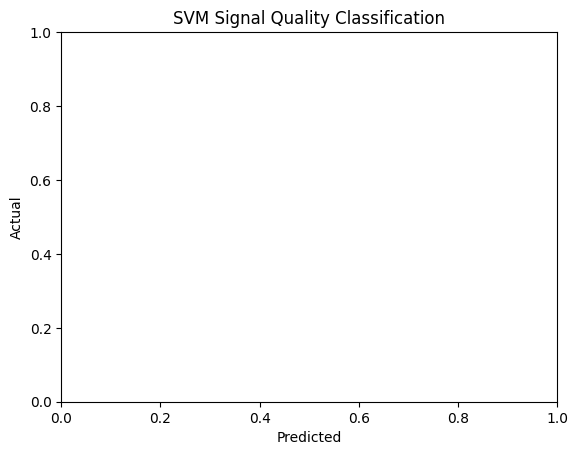

In [ ]:
plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("SVM Signal Quality Classification")

plt.show()


**11. Predict New Signal**

In [ ]:
new_signal = [[
    500,     # Distance_m (mapped from user's 'Distance')
    -65,     # Signal_Strength_dBm (mapped from user's 'RSSI')
    3,       # Frequency_GHz (mapped from user's 'Frequency Channel')
    -75,     # SNR_dB (mapped from user's 'SNR')
    0,       # Interference_dB (default value)
    20,      # Channel_Bandwidth_MHz (default value)
    -85,     # Noise_Floor_dBm (default value)
    20,      # Connected_Devices (default value)
    30       # Estimated_Throughput_Mbps (default value)
]]

In [ ]:
new_signal = scaler.transform(

    new_signal

)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
prediction = model.predict(

    new_signal

)

In [ ]:
print("\nNew Signal Quality:")

print(

    encoder.inverse_transform(
        prediction
    )[0]

)


New Signal Quality:
Poor
